In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
import sqlite3

from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm = ChatGroq(model='openai/gpt-oss-120b',temperature=0.1)
# memory = InMemorySaver()

conn = sqlite3.connect("workflow.db",check_same_thread=False)
memory = SqliteSaver(conn)

In [3]:
def chat_node(state: MessagesState) -> MessagesState:
    response = llm.invoke(state['messages'])
    return {
        'messages': [response]
    }

In [4]:
graph = StateGraph(MessagesState)

graph.add_node(chat_node)

graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

CONFIG = { 'configurable' :{ 'thread_id': '1'} }

workflow = graph.compile(checkpointer=memory)

In [5]:
workflow.invoke(
    {
        "messages": [
            HumanMessage(content="Hello there! My name is Vikas.")
        ]
    },
    config=CONFIG
)

{'messages': [HumanMessage(content='Hello there! My name is Vikas.', additional_kwargs={}, response_metadata={}, id='f07243d4-af36-4f97-88f6-87a0c89969d4'),
  AIMessage(content='Hello Vikas! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. We should respond friendly, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 80, 'total_tokens': 130, 'completion_time': 0.105810054, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003095488, 'prompt_tokens_details': None, 'queue_time': 0.395323416, 'total_time': 0.108905542}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a101d1-69d7-7342-95ca-ad95fa1528f1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 80, 'o

In [5]:
workflow.get_state(config=CONFIG)

StateSnapshot(values={'messages': [HumanMessage(content='Hello there! My name is Vikas.', additional_kwargs={}, response_metadata={}, id='f07243d4-af36-4f97-88f6-87a0c89969d4'), AIMessage(content='Hello Vikas! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. We should respond friendly, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 80, 'total_tokens': 130, 'completion_time': 0.105810054, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003095488, 'prompt_tokens_details': None, 'queue_time': 0.395323416, 'total_time': 0.108905542}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a101d1-69d7-7342-95ca-ad95fa1528f1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'in

In [6]:
workflow.invoke(
    {
        "messages": [
            HumanMessage(content="Hello there! Can you tell me my name.")
        ]
    },
    config=CONFIG
)

{'messages': [HumanMessage(content='Hello there! My name is Vikas.', additional_kwargs={}, response_metadata={}, id='f07243d4-af36-4f97-88f6-87a0c89969d4'),
  AIMessage(content='Hello Vikas! 👋 Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says hello, introduces themselves. We should respond friendly, ask how can help. No policy issues.'}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 80, 'total_tokens': 130, 'completion_time': 0.105810054, 'completion_tokens_details': {'reasoning_tokens': 23}, 'prompt_time': 0.003095488, 'prompt_tokens_details': None, 'queue_time': 0.395323416, 'total_time': 0.108905542}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a101d1-69d7-7342-95ca-ad95fa1528f1-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 80, 'o

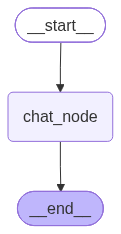

In [8]:
from IPython.display import display, Image
display(Image(workflow.get_graph().draw_mermaid_png()))